# makemore: becoming a backprop ninja

Manual backpropagation through a 2-layer MLP character model with BatchNorm, following Karpathy's
*Neural Networks: Zero to Hero*, lecture 4. Every gradient is derived by hand and checked against
PyTorch autograd. The network is then trained on those hand-written gradients alone, with no
`loss.backward()`.

| Exercise | What it does |
|---|---|
| 1 | Backprop through every intermediate tensor of the forward pass, one node at a time |
| 2 | Collapse the cross-entropy backward into one expression: `(softmax − one_hot) / n` |
| 3 | Collapse the BatchNorm backward into one expression |
| 4 | Train the full network with the manual backward pass |

See `README.md` for the derivations.

## Setup: data, vocabulary, dataset (same as the previous lecture)

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt  # for making figures
%matplotlib inline

In [2]:
# In Colab the dataset was downloaded with:
#   !wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
# The same file is included in this repo under data/.
words = open('data/names.txt', 'r').read().splitlines()
print(len(words))                    # number of names
print(max(len(w) for w in words))    # longest name
print(words[:8])

32033
15
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [3]:
# build the vocabulary of characters and mappings to/from integers
# '.' (index 0) marks both the start and the end of a name
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [4]:
# build the dataset: each example is (previous block_size characters) -> next character
block_size = 3  # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []
  for w in words:
    context = [0] * block_size          # start with '...'
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]      # slide the window: crop and append
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)                   # shuffle names before splitting
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% train
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% validation
Xte,  Yte  = build_dataset(words[n2:])     # 10% test

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
# compare a manually computed gradient `dt` with PyTorch's `t.grad`
#   exact:       bit-for-bit identical
#   approximate: equal up to floating-point round-off (torch.allclose)
#   maxdiff:     largest absolute difference
def cmp(s, dt, t):
  ex = torch.all(dt == t.grad).item()
  app = torch.allclose(dt, t.grad)
  maxdiff = (dt - t.grad).abs().max().item()
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

## The network and the "chunked" forward pass

`emb → concat → Linear(30→64) → BatchNorm → tanh → Linear(64→27) → cross-entropy`.

The forward pass is broken into many small steps, so each step has a simple local derivative.
`retain_grad()` makes PyTorch keep `.grad` on every intermediate, so each manual gradient can be
checked against it.

In [6]:
n_embd = 10    # dimensionality of the character embedding vectors
n_hidden = 64  # number of neurons in the hidden layer

g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
# Layer 1 (Kaiming-style init for tanh: gain 5/3 over sqrt(fan_in))
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                        generator=g) * 0.1  # redundant before BatchNorm; kept to exercise its gradient
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1
b2 = torch.randn(vocab_size,                      generator=g) * 0.1
# BatchNorm parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0
bnbias = torch.randn((1, n_hidden))*0.1

# Non-standard inits (e.g. random rather than zero biases) on purpose: an all-zeros init
# could hide a bug in the backward pass.
parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))  # number of parameters in total
for p in parameters:
  p.requires_grad = True

4137


In [7]:
batch_size = 32
n = batch_size  # shorter alias
# construct a minibatch
ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

In [8]:
# forward pass, "chunkated" into small steps that are easy to backprop through one at a time
#                                                     shapes (n=32)
emb = C[Xb]                                         # (32, 3, 10) embed the characters
embcat = emb.view(emb.shape[0], -1)                 # (32, 30)    concatenate the 3 vectors
# Linear layer 1
hprebn = embcat @ W1 + b1                           # (32, 64)    pre-BatchNorm activation
# BatchNorm layer
bnmeani = 1/n*hprebn.sum(0, keepdim=True)           # (1, 64)     batch mean
bndiff = hprebn - bnmeani                           # (32, 64)    x - mu
bndiff2 = bndiff**2                                 # (32, 64)
bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True)      # (1, 64)     batch variance, Bessel's correction (n-1)
bnvar_inv = (bnvar + 1e-5)**-0.5                    # (1, 64)     1 / sqrt(var + eps)
bnraw = bndiff * bnvar_inv                          # (32, 64)    normalised x_hat
hpreact = bngain * bnraw + bnbias                   # (32, 64)    scale and shift
# Non-linearity
h = torch.tanh(hpreact)                             # (32, 64)
# Linear layer 2
logits = h @ W2 + b2                                # (32, 27)
# cross-entropy loss, written out (same as F.cross_entropy(logits, Yb))
logit_maxes = logits.max(1, keepdim=True).values    # (32, 1)
norm_logits = logits - logit_maxes                  # (32, 27)    subtract row max for numerical stability
counts = norm_logits.exp()                          # (32, 27)
counts_sum = counts.sum(1, keepdims=True)           # (32, 1)
counts_sum_inv = counts_sum**-1                     # (32, 1)     (1.0/counts_sum would not be bit-exact in backprop)
probs = counts * counts_sum_inv                     # (32, 27)    softmax
logprobs = probs.log()                              # (32, 27)
loss = -logprobs[range(n), Yb].mean()               # scalar      mean negative log-likelihood of the targets

# PyTorch backward pass, for reference
for p in parameters:
  p.grad = None
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv,  # keep .grad on intermediates
          norm_logits, logit_maxes, logits, h, hpreact, bnraw,
          bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmeani,
          embcat, emb]:
  t.retain_grad()
loss.backward()
loss

tensor(3.3372, grad_fn=<NegBackward0>)

## Exercise 1: backprop through every node

Walk the graph backwards. At each node: **gradient = local derivative × upstream gradient**,
summed over every place the node is used. Two patterns come up again and again:

- **Broadcast forward ⇔ sum backward.** If a `(1, 64)` or `(32, 1)` tensor was broadcast in the
  forward pass, its gradient is summed over the broadcast dimension.
- **Sum forward ⇔ broadcast backward.** If a tensor was reduced with `.sum`, its gradient is copied
  back to every summed element.

A gradient always has the same shape as the tensor it belongs to; that alone catches most mistakes.

In [9]:
# loss = -(1/n) * sum_i logprobs[i, Yb[i]]
# only the n "correct" entries enter the loss, each with weight -1/n; everything else gets 0
dlogprobs = torch.zeros_like(logprobs)
dlogprobs[range(n), Yb] = -1.0/n
cmp('logprobs', dlogprobs, logprobs)

# logprobs = log(probs)               d/dx log x = 1/x
dprobs = (1.0/probs) * dlogprobs
cmp('probs', dprobs, probs)

# probs = counts * counts_sum_inv     counts_sum_inv (32,1) was broadcast over 27 columns -> sum over dim 1
dcounts_sum_inv = (counts * dprobs).sum(1, keepdim=True)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)

# counts_sum_inv = counts_sum**-1     d/dx x^-1 = -x^-2
dcounts_sum = -1.0 * counts_sum**-2 * dcounts_sum_inv
cmp('counts_sum', dcounts_sum, counts_sum)

# counts is used twice: in probs (directly) and in counts_sum (a row sum -> broadcast back)
dcounts = counts_sum_inv * dprobs + torch.ones_like(counts) * dcounts_sum
cmp('counts', dcounts, counts)

# counts = exp(norm_logits)           d/dx e^x = e^x = counts
dnorm_logits = counts * dcounts
cmp('norm_logits', dnorm_logits, norm_logits)

# norm_logits = logits - logit_maxes
#   logits gets the gradient as-is; logit_maxes (32,1) was broadcast -> negative row sum.
#   dlogit_maxes is ~0: softmax is shift-invariant, so the max only matters for stability.
dlogits = dnorm_logits.clone()
dlogit_maxes = (-dnorm_logits).sum(1, keepdim=True)
cmp('logit_maxes', dlogit_maxes, logit_maxes)

# logit_maxes = logits.max(1)         the max routes its gradient only to the argmax position
max_mask = F.one_hot(logits.argmax(1), num_classes=logits.shape[1])
dlogits += max_mask * dlogit_maxes
cmp('logits', dlogits, logits)

# logits = h @ W2 + b2                matmul backward: transpose and match shapes
dh = dlogits @ W2.T                   # (32,27) @ (27,64) -> (32,64)
cmp('h', dh, h)
dW2 = h.T @ dlogits                   # (64,32) @ (32,27) -> (64,27)
cmp('W2', dW2, W2)
db2 = dlogits.sum(0)                  # b2 broadcast over the batch -> sum over dim 0
cmp('b2', db2, b2)

# h = tanh(hpreact)                   d/dx tanh x = 1 - tanh^2 x = 1 - h^2
dhpreact = (1.0 - h**2) * dh
cmp('hpreact', dhpreact, hpreact)

# hpreact = bngain * bnraw + bnbias   bngain, bnbias are (1,64), broadcast over the batch
dbngain = (bnraw * dhpreact).sum(0, keepdim=True)
cmp('bngain', dbngain, bngain)
dbnbias = dhpreact.sum(0, keepdim=True)
cmp('bnbias', dbnbias, bnbias)
dbnraw = bngain * dhpreact
cmp('bnraw', dbnraw, bnraw)

# bnraw = bndiff * bnvar_inv          bnvar_inv (1,64) broadcast -> sum over dim 0
dbnvar_inv = (bndiff * dbnraw).sum(0, keepdim=True)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)
dbndiff = bnvar_inv * dbnraw          # first of bndiff's two contributions (finished below)

# bnvar_inv = (bnvar + eps)**-0.5     d/dx x^-0.5 = -0.5 x^-1.5
dbnvar = (-0.5 * (bnvar + 1e-5)**-1.5) * dbnvar_inv
cmp('bnvar', dbnvar, bnvar)

# bnvar = 1/(n-1) * sum_i bndiff2     sum -> broadcast back, scaled by 1/(n-1)
dbndiff2 = (1.0/(n-1)) * torch.ones_like(bndiff2) * dbnvar
cmp('bndiff2', dbndiff2, bndiff2)

# bndiff2 = bndiff**2                 second contribution to bndiff: 2x
dbndiff += 2 * bndiff * dbndiff2
cmp('bndiff', dbndiff, bndiff)

# bndiff = hprebn - bnmeani           bnmeani (1,64) broadcast -> negative sum over dim 0
dbnmeani = (-dbndiff).sum(0, keepdim=True)
cmp('bnmeani', dbnmeani, bnmeani)

# hprebn feeds bndiff directly and bnmeani = (1/n) * sum_i hprebn (sum -> broadcast back)
dhprebn = dbndiff.clone() + (1.0/n) * torch.ones_like(hprebn) * dbnmeani
cmp('hprebn', dhprebn, hprebn)

# hprebn = embcat @ W1 + b1           same matmul pattern as layer 2
dembcat = dhprebn @ W1.T              # (32,64) @ (64,30) -> (32,30)
cmp('embcat', dembcat, embcat)
dW1 = embcat.T @ dhprebn              # (30,32) @ (32,64) -> (30,64)
cmp('W1', dW1, W1)
db1 = dhprebn.sum(0)
cmp('b1', db1, b1)

# embcat = emb.view(32, 30)           a view only reshapes -> reshape the gradient back
demb = dembcat.view(emb.shape)
cmp('emb', demb, emb)

# emb = C[Xb]                         a lookup: each row of C used k times gets k gradients added
dC = torch.zeros_like(C)
for i in range(Xb.shape[0]):
  for j in range(Xb.shape[1]):
    ix = Xb[i, j]
    dC[ix] += demb[i, j]
cmp('C', dC, C)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logit_maxes     | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
hpreact         | exact: False | approximate: True  | maxdiff: 4.656612873077393e-10
bngain          | exact: False | approximate: True  | maxdiff: 2.7939677238464355e-09
bnbias          | exact: False | approximate: True  | maxdiff: 3.725290298461914e-09
bnraw  

Everything matches. Everything from the loss down to `W2`/`b2` is bit-exact. From `hpreact` down,
PyTorch computes the same maths in a different order, so the match is to ~1e-9 (floating-point round-off).

## Exercise 2: cross-entropy backward in one line

For one row, with $p = \mathrm{softmax}(\ell)$ and target $y$: $L = -\log p_y$, so
$\partial L / \partial \ell_j = p_j - \mathbb{1}[j = y]$. Averaging over the batch divides by $n$.

In [10]:
# forward: the 8 lines of the explicit cross-entropy collapse into one fused call
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff:', (loss_fast - loss).item())

3.337174415588379 diff: 0.0


In [11]:
# backward: dL/dlogits = (softmax(logits) - one_hot(Yb)) / n
# Intuition: each row pulls down on every wrong class in proportion to its probability and pushes up
# on the correct class by (1 - p_correct). Each row of dlogits sums to 0.
y = F.one_hot(Yb, num_classes=vocab_size)
dlogits = (F.softmax(logits, dim=1) - y) / n
cmp('logits', dlogits, logits)

logits          | exact: False | approximate: True  | maxdiff: 7.683411240577698e-09


## Exercise 3: BatchNorm backward in one line

With $\hat x = (x - \mu)/\sqrt{\sigma^2 + \epsilon}$, $\sigma^2 = \frac{1}{n-1}\sum_i (x_i-\mu)^2$
and $y = \gamma \hat x + \beta$, each output depends on every input in its column (through $\mu$ and
$\sigma^2$). Summing those paths and simplifying gives

$$\frac{\partial L}{\partial x_i} = \frac{\gamma}{n\sqrt{\sigma^2+\epsilon}}\Big(n\,\frac{\partial L}{\partial y_i} - \sum_j \frac{\partial L}{\partial y_j} - \frac{n}{n-1}\,\hat x_i \sum_j \frac{\partial L}{\partial y_j}\,\hat x_j\Big)$$

The full derivation is in the README.

In [12]:
# forward: the 7 BatchNorm lines in one expression
hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdim=True)) / torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5) + bnbias
print('max diff:', (hpreact_fast - hpreact).abs().max())

max diff: tensor(4.7684e-07, grad_fn=<MaxBackward1>)


In [13]:
# backward: dL/dhprebn from dL/dhpreact in one line
#   n * dhpreact                          direct path through x_i
#   - dhpreact.sum(0)                     path through the mean mu
#   - n/(n-1) * bnraw * (...).sum(0)      path through the variance (n-1 from Bessel's correction)
# The (64,) sums broadcast across the 32 rows; everything is scaled by gamma / (n * sigma).
dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n/(n-1) * bnraw * (dhpreact * bnraw).sum(0))
cmp('hprebn', dhprebn, hprebn)  # approximate only; maxdiff ~1e-9

hprebn          | exact: False | approximate: True  | maxdiff: 9.313225746154785e-10


## Exercise 4: train with the manual backward pass

The backward pass from Exercises 2 and 3, plus the matmul, tanh and embedding steps from
Exercise 1, goes into one function. It is checked against autograd on one batch, then used
**alone** to train the network: the loop runs under `torch.no_grad()` and never calls
`loss.backward()`.

In [14]:
# init: same architecture, wider hidden layer
n_embd = 10    # dimensionality of the character embedding vectors
n_hidden = 200 # number of neurons in the hidden layer

g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
# Layer 1
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                        generator=g) * 0.1
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1
b2 = torch.randn(vocab_size,                      generator=g) * 0.1
# BatchNorm parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0
bnbias = torch.randn((1, n_hidden))*0.1

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))  # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [15]:
def forward(Xb, Yb):
  """Training-mode forward pass (BatchNorm uses batch statistics). Returns the loss and a
  cache of the intermediates the backward pass needs."""
  emb = C[Xb]                                   # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1)           # concatenate the vectors
  hprebn = embcat @ W1 + b1                     # Linear layer 1
  bnmean = hprebn.mean(0, keepdim=True)         # BatchNorm
  bnvar = hprebn.var(0, keepdim=True, unbiased=True)
  bnvar_inv = (bnvar + 1e-5)**-0.5
  bnraw = (hprebn - bnmean) * bnvar_inv
  hpreact = bngain * bnraw + bnbias
  h = torch.tanh(hpreact)                       # non-linearity
  logits = h @ W2 + b2                          # Linear layer 2
  loss = F.cross_entropy(logits, Yb)
  return loss, (emb, embcat, bnvar_inv, bnraw, h, logits)


def manual_backward(Xb, Yb, cache):
  """Gradients of the loss w.r.t. every parameter, derived by hand. Returns them in the same order as `parameters`."""
  emb, embcat, bnvar_inv, bnraw, h, logits = cache
  n = Xb.shape[0]
  # cross-entropy (Exercise 2): (softmax - one_hot) / n
  dlogits = F.softmax(logits, dim=1)
  dlogits[range(n), Yb] -= 1
  dlogits /= n
  # Linear layer 2
  dh = dlogits @ W2.T
  dW2 = h.T @ dlogits
  db2 = dlogits.sum(0)
  # tanh
  dhpreact = (1.0 - h**2) * dh
  # BatchNorm scale/shift, then the one-line BatchNorm backward (Exercise 3)
  dbngain = (bnraw * dhpreact).sum(0, keepdim=True)
  dbnbias = dhpreact.sum(0, keepdim=True)
  dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n/(n-1) * bnraw * (dhpreact * bnraw).sum(0))
  # Linear layer 1
  dembcat = dhprebn @ W1.T
  dW1 = embcat.T @ dhprebn
  db1 = dhprebn.sum(0)
  # embedding lookup: scatter-add each row's gradient into C.
  # index_add_ does the same as the double for-loop in Exercise 1, in one vectorised call.
  demb = dembcat.view(emb.shape)
  dC = torch.zeros_like(C)
  dC.index_add_(0, Xb.view(-1), demb.view(-1, n_embd))
  return [dC, dW1, db1, dW2, db2, dbngain, dbnbias]

In [16]:
# gradient check: one batch through autograd vs manual_backward.
# A separate generator is used, so the training run below draws exactly the same batches as before.
gcheck = torch.Generator().manual_seed(42)
ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=gcheck)
Xb, Yb = Xtr[ix], Ytr[ix]
for p in parameters:
  p.grad = None
loss, cache = forward(Xb, Yb)
loss.backward()
with torch.no_grad():
  grads = manual_backward(Xb, Yb, cache)
for name, p, grad in zip(['C', 'W1', 'b1', 'W2', 'b2', 'bngain', 'bnbias'], parameters, grads):
  cmp(f'{name} {tuple(p.shape)}', grad, p)

C (27, 10)      | exact: False | approximate: True  | maxdiff: 2.2351741790771484e-08
W1 (30, 200)    | exact: False | approximate: True  | maxdiff: 1.1175870895385742e-08
b1 (200,)       | exact: False | approximate: True  | maxdiff: 5.587935447692871e-09
W2 (200, 27)    | exact: False | approximate: True  | maxdiff: 2.2351741790771484e-08
b2 (27,)        | exact: False | approximate: True  | maxdiff: 7.450580596923828e-09
bngain (1, 200) | exact: False | approximate: True  | maxdiff: 3.725290298461914e-09
bnbias (1, 200) | exact: False | approximate: True  | maxdiff: 7.450580596923828e-09


In [17]:
# training: manual gradients only
max_steps = 200000
batch_size = 32
n = batch_size
lossi = []

with torch.no_grad():  # no autograd graph is needed any more
  for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward and manual backward pass
    loss, cache = forward(Xb, Yb)
    grads = manual_backward(Xb, Yb, cache)

    # SGD update with step learning-rate decay
    lr = 0.1 if i < 100000 else 0.01
    for p, grad in zip(parameters, grads):
      p.data += -lr * grad

    # track stats
    if i % 10000 == 0:
      print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.8172
  10000/ 200000: 2.1638
  20000/ 200000: 2.4153
  30000/ 200000: 2.4689
  40000/ 200000: 2.0311
  50000/ 200000: 2.4076
  60000/ 200000: 2.3409
  70000/ 200000: 2.0203
  80000/ 200000: 2.3155
  90000/ 200000: 2.1249
 100000/ 200000: 1.9783
 110000/ 200000: 2.2892
 120000/ 200000: 1.9881
 130000/ 200000: 2.4261
 140000/ 200000: 2.2075
 150000/ 200000: 2.1337
 160000/ 200000: 1.9525
 170000/ 200000: 1.8314
 180000/ 200000: 1.9523
 190000/ 200000: 1.9012


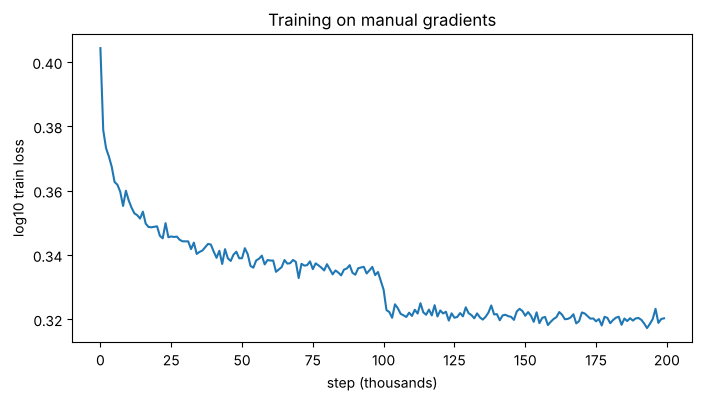

In [18]:
# training loss (log10), averaged over windows of 1,000 steps to smooth out mini-batch noise
plt.figure(figsize=(8, 4))
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
plt.xlabel('step (thousands)')
plt.ylabel('log10 train loss')
plt.title('Training on manual gradients');

## Evaluation and sampling

In [19]:
# calibrate BatchNorm at the end of training: replace per-batch statistics with the mean and
# variance over the entire training set, so inference doesn't depend on a batch.
with torch.no_grad():
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [20]:
@torch.no_grad()  # disables gradient tracking
def split_loss(split):
  x, y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x]                                    # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1)           # (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias  # BatchNorm with calibrated stats
  h = torch.tanh(hpreact)                       # (N, n_hidden)
  logits = h @ W2 + b2                          # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')
# Karpathy's reference with the same recipe: train 2.0719, val 2.1162

train 2.069599151611328
val 2.11017107963562


In [21]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out = []
  context = [0] * block_size  # start with '...'
  while True:
    emb = C[torch.tensor([context])]            # (1, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()  # sample the next character
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:  # '.' ends the name
      break
  print(''.join(itos[i] for i in out))

carmahxaan.
harli.
jari.
reetlanna.
sane.
mahnen.
den.
arcie.
qui.
nellara.
chaiha.
kaleigh.
ham.
joce.
quinn.
shoine.
liveni.
waterra.
jarynix.
kaellissa.
